In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [3]:
train = pd.read_csv(
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv"
)

test = pd.read_csv(
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv"
)

In [4]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)


Train shape: (1460, 81)
Test shape: (1459, 80)


In [5]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [6]:
missing_percent = (train.isnull().sum() / len(train) * 100)

missing_summary = pd.DataFrame({
    "Missing": train.isnull().sum(),
    "Percentage": missing_percent
})

missing_summary = missing_summary[missing_summary["Missing"] > 0]
missing_summary = missing_summary.sort_values("Missing", ascending=False)

missing_summary

,Missing,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [7]:
cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "MasVnrType",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "BsmtQual",
    "BsmtCond"
]

train[cols].isnull().sum()

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
GarageType        81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
dtype: int64

In [8]:
description_path = "/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt"

with open(description_path, "r") as file:
    description = file.read()

print(description[:8000])

MSSubClass: Identifies the type of dwelling involved in the sale.	

        20	1-STORY 1946 & NEWER ALL STYLES
        30	1-STORY 1945 & OLDER
        40	1-STORY W/FINISHED ATTIC ALL AGES
        45	1-1/2 STORY - UNFINISHED ALL AGES
        50	1-1/2 STORY FINISHED ALL AGES
        60	2-STORY 1946 & NEWER
        70	2-STORY 1945 & OLDER
        75	2-1/2 STORY ALL AGES
        80	SPLIT OR MULTI-LEVEL
        85	SPLIT FOYER
        90	DUPLEX - ALL STYLES AND AGES
       120	1-STORY PUD (Planned Unit Development) - 1946 & NEWER
       150	1-1/2 STORY PUD - ALL AGES
       160	2-STORY PUD - 1946 & NEWER
       180	PUD - MULTILEVEL - INCL SPLIT LEV/FOYER
       190	2 FAMILY CONVERSION - ALL STYLES AND AGES

MSZoning: Identifies the general zoning classification of the sale.
		
       A	Agriculture
       C	Commercial
       FV	Floating Village Residential
       I	Industrial
       RH	Residential High Density
       RL	Residential Low Density
       RP	Residential Low Density Park 
       RM

In [9]:
missing_cols = [
    "PoolQC",
    "MiscFeature",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "LotFrontage",
    "MasVnrType",
    "MasVnrArea",
    "Electrical"
]

for col in missing_cols:
    start = description.find(col + ":")
    if start != -1:
        print("\n" + "=" * 50)
        print(description[start:start + 500])


PoolQC: Pool quality
		
       Ex	Excellent
       Gd	Good
       TA	Average/Typical
       Fa	Fair
       NA	No Pool
		
Fence: Fence quality
		
       GdPrv	Good Privacy
       MnPrv	Minimum Privacy
       GdWo	Good Wood
       MnWw	Minimum Wood/Wire
       NA	No Fence
	
MiscFeature: Miscellaneous feature not covered in other categories
		
       Elev	Elevator
       Gar2	2nd Garage (if not described in garage section)
       Othr	Other
       Shed	Shed (over 100 SF)
       TenC	Tennis Court
  

MiscFeature: Miscellaneous feature not covered in other categories
		
       Elev	Elevator
       Gar2	2nd Garage (if not described in garage section)
       Othr	Other
       Shed	Shed (over 100 SF)
       TenC	Tennis Court
       NA	None
		
MiscVal: $Value of miscellaneous feature

MoSold: Month Sold (MM)

YrSold: Year Sold (YYYY)

SaleType: Type of sale
		
       WD 	Warranty Deed - Conventional
       CWD	Warranty Deed - Cash
       VWD	Warranty Deed - VA Loan
       New	Home just constru

In [10]:
none_cols = [
    "PoolQC",
    "MiscFeature",
    "Alley",
    "Fence",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "BsmtQual",
    "BsmtCond",
    "MasVnrType"
]

train[none_cols] = train[none_cols].fillna("None")
test[none_cols] = test[none_cols].fillna("None")
train[none_cols].isnull().sum()

PoolQC          0
MiscFeature     0
Alley           0
Fence           0
FireplaceQu     0
GarageType      0
GarageFinish    0
GarageQual      0
GarageCond      0
BsmtExposure    0
BsmtFinType1    0
BsmtFinType2    0
BsmtQual        0
BsmtCond        0
MasVnrType      0
dtype: int64

In [11]:
remaining_missing = train.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)

remaining_missing

LotFrontage    259
GarageYrBlt     81
MasVnrArea       8
Electrical       1
dtype: int64

In [12]:
train["LotFrontage"] = train.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

test["LotFrontage"] = test.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)
train["LotFrontage"].isnull().sum()
test["LotFrontage"].isnull().sum()

np.int64(0)

In [13]:
train["GarageYrBlt"] = train["GarageYrBlt"].fillna(0)
test["GarageYrBlt"] = test["GarageYrBlt"].fillna(0)
train["GarageYrBlt"].isnull().sum()

np.int64(0)

In [14]:
train["MasVnrArea"] = train["MasVnrArea"].fillna(0)
test["MasVnrArea"] = test["MasVnrArea"].fillna(0)
train["MasVnrArea"].isnull().sum()
train["Electrical"].value_counts(dropna=False)

Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64

In [15]:
train["Electrical"] = train["Electrical"].fillna(train["Electrical"].mode()[0])
test["Electrical"] = test["Electrical"].fillna(test["Electrical"].mode()[0])
print("Train missing values:", train.isnull().sum().sum())
print("Test missing values:", test.isnull().sum().sum())

Train missing values: 0
Test missing values: 22


In [16]:
test_missing = test.isnull().sum()
test_missing = test_missing[test_missing > 0].sort_values(ascending=False)

test_missing

MSZoning        4
Utilities       2
BsmtFullBath    2
BsmtHalfBath    2
Functional      2
Exterior2nd     1
Exterior1st     1
BsmtUnfSF       1
BsmtFinSF2      1
BsmtFinSF1      1
TotalBsmtSF     1
KitchenQual     1
GarageCars      1
GarageArea      1
SaleType        1
dtype: int64

In [17]:
cols = [
    "MSZoning",
    "Utilities",
    "BsmtFullBath",
    "BsmtHalfBath",
    "Functional",
    "Exterior2nd",
    "Exterior1st",
    "BsmtUnfSF",
    "BsmtFinSF2",
    "BsmtFinSF1",
    "TotalBsmtSF",
    "KitchenQual",
    "GarageCars",
    "GarageArea",
    "SaleType"
]

test[cols].dtypes

MSZoning         object
Utilities        object
BsmtFullBath    float64
BsmtHalfBath    float64
Functional       object
Exterior2nd      object
Exterior1st      object
BsmtUnfSF       float64
BsmtFinSF2      float64
BsmtFinSF1      float64
TotalBsmtSF     float64
KitchenQual      object
GarageCars      float64
GarageArea      float64
SaleType         object
dtype: object

In [18]:
cat_cols = [
    "MSZoning",
    "Utilities",
    "Functional",
    "Exterior2nd",
    "Exterior1st",
    "KitchenQual",
    "SaleType"
]

for col in cat_cols:
    test[col] = test[col].fillna(train[col].mode()[0])
test[cat_cols].isnull().sum()

MSZoning       0
Utilities      0
Functional     0
Exterior2nd    0
Exterior1st    0
KitchenQual    0
SaleType       0
dtype: int64

In [19]:
num_cols = [
    "BsmtFullBath",
    "BsmtHalfBath",
    "BsmtUnfSF",
    "BsmtFinSF2",
    "BsmtFinSF1",
    "TotalBsmtSF",
    "GarageCars",
    "GarageArea"
]

test[num_cols] = test[num_cols].fillna(0)
print("Train missing values:", train.isnull().sum().sum())
print("Test missing values:", test.isnull().sum().sum())

Train missing values: 0
Test missing values: 0


In [20]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

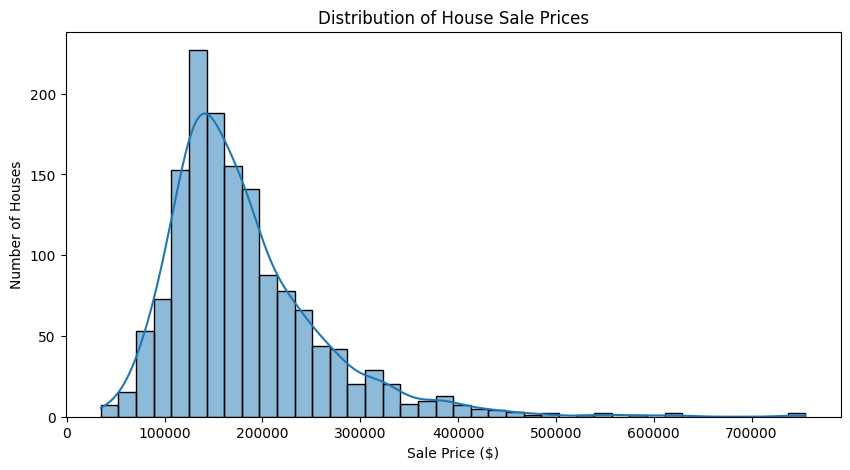

In [21]:
plt.figure(figsize=(10, 5))

sns.histplot(train["SalePrice"], bins=40, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()

In [22]:
print("Skewness:", train["SalePrice"].skew())

Skewness: 1.8828757597682129


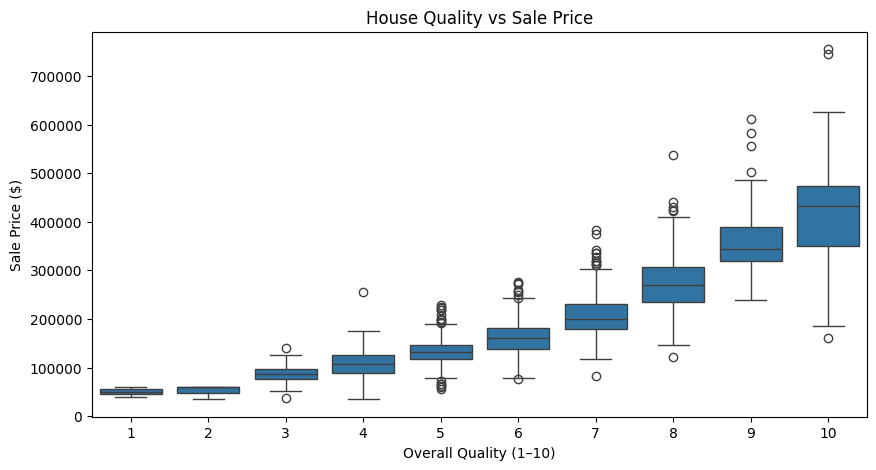

In [23]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=train, x="OverallQual", y="SalePrice")

plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality (1–10)")
plt.ylabel("Sale Price ($)")

plt.show()

In [24]:
train[["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "SalePrice"]].corr()["SalePrice"].sort_values(ascending=False)

SalePrice      1.000000
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64

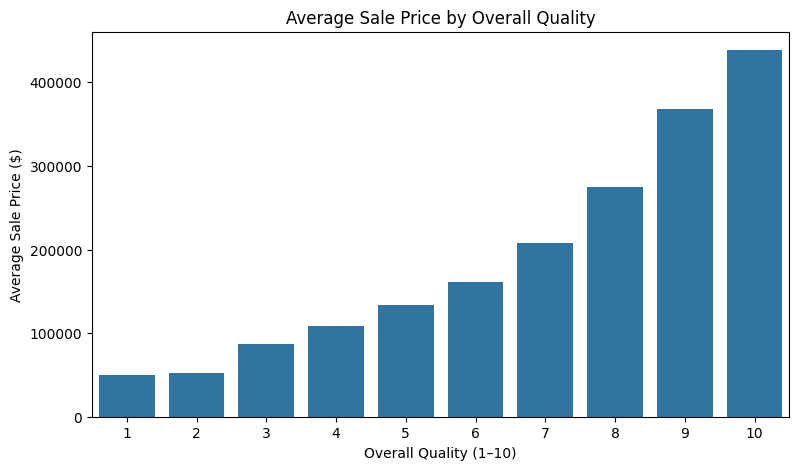

In [25]:
plt.figure(figsize=(9, 5))

sns.barplot(data=train, x="OverallQual", y="SalePrice", errorbar=None)

plt.title("Average Sale Price by Overall Quality")
plt.xlabel("Overall Quality (1–10)")
plt.ylabel("Average Sale Price ($)")

plt.show()

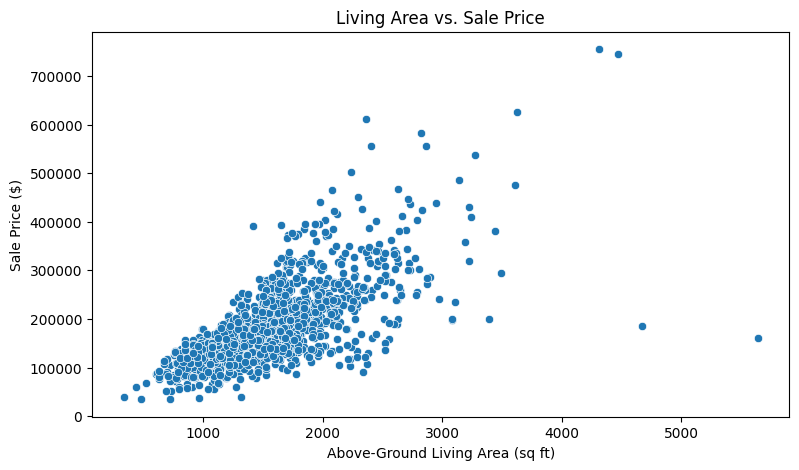

In [26]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=train,
    x="GrLivArea",
    y="SalePrice"
)

plt.title("Living Area vs. Sale Price")
plt.xlabel("Above-Ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")

plt.show()

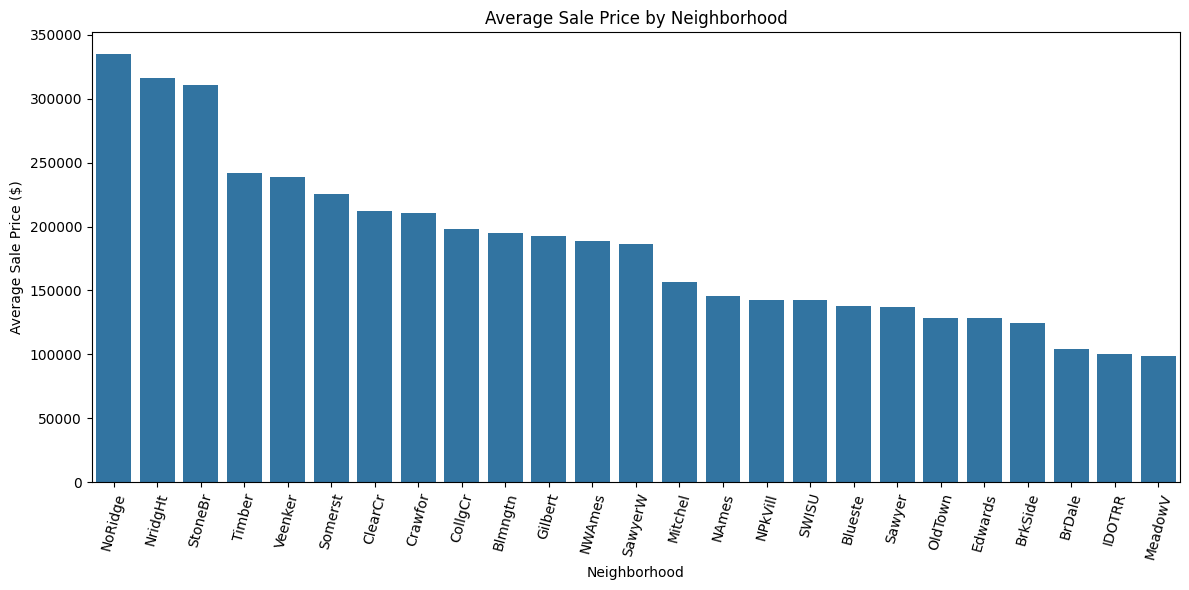

In [27]:
neighborhood_prices = (
    train.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=neighborhood_prices.index,
    y=neighborhood_prices.values
)

plt.title("Average Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Average Sale Price ($)")
plt.xticks(rotation=75)

plt.tight_layout()
plt.show()

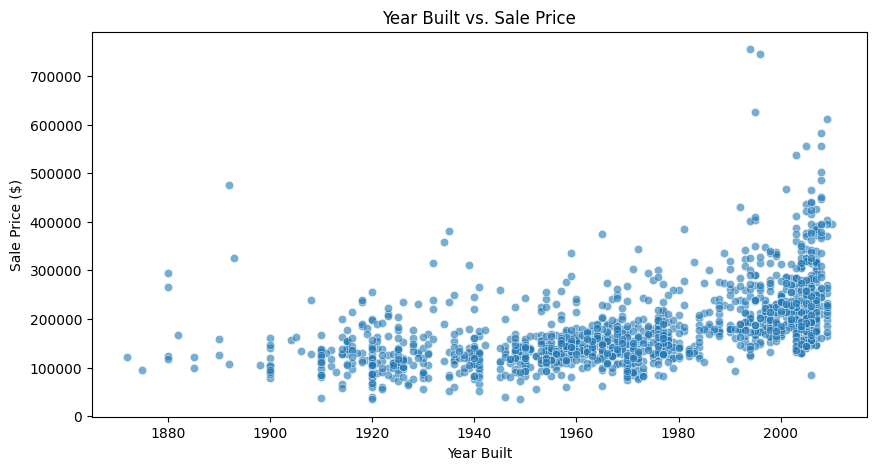

In [28]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=train,
    x="YearBuilt",
    y="SalePrice",
    alpha=0.6
)

plt.title("Year Built vs. Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price ($)")

plt.show()

In [29]:
print("HOUSE PRICES — EDA SUMMARY")
print("-" * 35)

print(f"Training houses: {train.shape[0]}")
print(f"Test houses: {test.shape[0]}")
print(f"Average sale price: ${train['SalePrice'].mean():,.0f}")
print(f"Median sale price: ${train['SalePrice'].median():,.0f}")
print(f"Sale price skewness: {train['SalePrice'].skew():.2f}")

print("\nTop 5 correlated features:")
print(
    train.corr(numeric_only=True)["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
    .head(5)
)

HOUSE PRICES — EDA SUMMARY
-----------------------------------
Training houses: 1460
Test houses: 1459
Average sale price: $180,921
Median sale price: $163,000
Sale price skewness: 1.88

Top 5 correlated features:
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
GarageArea     0.623431
TotalBsmtSF    0.613581
Name: SalePrice, dtype: float64


In [30]:
#Separate features (X) and target (y)
# Separate the target from the training features
X = train.drop(columns=["SalePrice", "Id"])
y = np.log1p(train["SalePrice"])

# Keep test IDs for our eventual Kaggle submission
test_ids = test["Id"]

# Remove Id from the test features too
X_test = test.drop(columns=["Id"])

print("Training features:", X.shape)
print("Target:", y.shape)
print("Test features:", X_test.shape)

print("\nTarget preview (log-transformed prices):")
print(y.head())

Training features: (1460, 79)
Target: (1460,)
Test features: (1459, 79)

Target preview (log-transformed prices):
0    12.247699
1    12.109016
2    12.317171
3    11.849405
4    12.429220
Name: SalePrice, dtype: float64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)

Training: (1168, 79)
Validation: (292, 79)


In [32]:
#Convert categorical features into numbers
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

num_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

cat_features = X.select_dtypes(
    include=["object", "category"]
).columns


preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
    ]
)

print("Numerical features:", len(num_features))
print("Categorical features:", len(cat_features))

Numerical features: 36
Categorical features: 43


In [33]:
#TRAIN OUR FIRST RANDOM FOREST MODEL
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Training model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [34]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Predicting prices for validation houses
y_pred = model.predict(X_valid)

# Calculate error on log-transformed prices
rmse_log = np.sqrt(mean_squared_error(y_valid, y_pred))

# Converting predictions back to actual house prices
predicted_prices = np.expm1(y_pred)
actual_prices = np.expm1(y_valid)

print(f"Validation Log RMSE: {rmse_log:.5f}")

print("\nFirst 5 predictions:")
for actual, predicted in zip(actual_prices[:5], predicted_prices[:5]):
    print(f"Actual: ${actual:,.0f} | Predicted: ${predicted:,.0f}")

Validation Log RMSE: 0.14600

First 5 predictions:
Actual: $154,500 | Predicted: $140,403
Actual: $325,000 | Predicted: $324,303
Actual: $115,000 | Predicted: $116,990
Actual: $159,000 | Predicted: $154,618
Actual: $315,500 | Predicted: $316,742


In [35]:
# Predictions on training data
train_predictions = model.predict(X_train)

# Predictions on validation data
valid_predictions = model.predict(X_valid)

# Calculate errors
train_rmse = np.sqrt(
    mean_squared_error(y_train, train_predictions)
)

valid_rmse = np.sqrt(
    mean_squared_error(y_valid, valid_predictions)
)

print(f"Training Log RMSE:   {train_rmse:.5f}")
print(f"Validation Log RMSE: {valid_rmse:.5f}")
print(f"Difference:          {valid_rmse - train_rmse:.5f}")

Training Log RMSE:   0.05363
Validation Log RMSE: 0.14600
Difference:          0.09237


In [36]:
improved_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

improved_model.fit(X_train, y_train)

train_pred_new = improved_model.predict(X_train)
valid_pred_new = improved_model.predict(X_valid)

train_score_new = np.sqrt(
    mean_squared_error(y_train, train_pred_new)
)

valid_score_new = np.sqrt(
    mean_squared_error(y_valid, valid_pred_new)
)

print(f"New Training Log RMSE:   {train_score_new:.5f}")
print(f"New Validation Log RMSE: {valid_score_new:.5f}")
print(f"Old Validation Log RMSE: {valid_rmse:.5f}")

New Training Log RMSE:   0.07600
New Validation Log RMSE: 0.14585
Old Validation Log RMSE: 0.14600


In [37]:
from sklearn.model_selection import cross_val_score

cv_scores = -cross_val_score(
    improved_model,
    X,
    y,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

print("Cross-validation scores:", cv_scores)
print(f"Mean CV Log RMSE: {cv_scores.mean():.5f}")
print(f"Standard deviation: {cv_scores.std():.5f}")

Cross-validation scores: [0.13893303 0.15555509 0.14561127 0.12955771 0.15365247]
Mean CV Log RMSE: 0.14466
Standard deviation: 0.00961


In [38]:
# Train final model using all training houses
improved_model.fit(X, y)

test_predictions_log = improved_model.predict(X_test)

test_predictions = np.expm1(test_predictions_log)

print("Final model trained successfully!")
print("Number of predictions:", len(test_predictions))
print("First 5 predicted prices:", test_predictions[:5])

Final model trained successfully!
Number of predictions: 1459
First 5 predicted prices: [126109.19848616 153815.57823272 177032.80378743 181968.45748423
 194917.50825042]


In [39]:
submission = pd.DataFrame({
    "Id": test_ids,
    "SalePrice": test_predictions
})

submission.to_csv("/kaggle/working/submission.csv", index=False)

print("Submission shape:", submission.shape)
print("\nFirst 5 rows:")
print(submission.head())

print("\nMissing values:")
print(submission.isnull().sum())

Submission shape: (1459, 2)

First 5 rows:
     Id      SalePrice
0  1461  126109.198486
1  1462  153815.578233
2  1463  177032.803787
3  1464  181968.457484
4  1465  194917.508250

Missing values:
Id           0
SalePrice    0
dtype: int64
